# 06 - Noise model: kernels on a simulated IBM device (week 2)
Owner: **Shams**

So far every quantum number came from a perfect simulator: **exact** (no shot noise) or **sampled** (2048 shots, no device errors). Real hardware also has gate errors, readout errors and decoherence. Here we rerun both quantum kernels on a **noise model copied from a real IBM device** (synopsis Sec. IV-C):

- Device: `ibm_kingston` (156-qubit Heron), the backend of our week 1 test job, via IBM's published calibration snapshot (`FakeKingston`). Fixed snapshot = reproducible, no hardware time used.
- Circuits are transpiled to the device's native gates and qubits, so they are the circuits the hardware would run.
- **Same images, same encoding settings, same shots (2048)** as the ideal runs; settings ($\alpha$, $\gamma$ scale, $C$) are the ones already chosen in notebooks 02 and 03, **not re-tuned**. For the projected kernel, $\gamma$ is recomputed from the noisy training features by the same median rule.
- Three levels per kernel: **exact -> sampled -> noisy**. Week 3 adds the fourth: real hardware.
- Enhancement over Huang et al.: we also compute the geometric difference $g$ from the **noisy** kernels, to see whether device noise changes $g$.

In [4]:
import sys, json, time
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from src.common import (get_split, make_preprocessor, encoding_circuit, evaluate_precomputed,
                        mean_offdiag, min_eig, result_path, RESULTS, SEEDS, SHOTS)
from src.projected import pauli_features_exact, pauli_features_sampled, projected_kernel, median_gamma
from src.baselines import classical_gram
from src.geometry import geometric_difference
from src.noise import (noisy_simulator, pauli_features_noisy, fidelity_kernel_noisy,
                       noisy_resources, BACKEND_NAME)

## 1. Settings and transpiled circuit sizes

In [5]:
N_LIST = [2, 4, 6, 8]
LAYERS = 2
KINDS = {"SVM RBF (tuned)": "rbf", "SVM polynomial (tuned)": "poly", "SVM linear (tuned)": "linear"}
a_tag = lambda a: f"{a:.3f}".replace(".", "p")          # same file names as notebook 02

def load(name, seed, n):
    return json.loads(result_path("tables", name, seed, n, "json").read_text())

noisy_simulator()                                       # build the noise model once
print("noise model:", BACKEND_NAME, "| shots per circuit:", SHOTS)
resources = {}
for n in N_LIST:
    resources[n] = noisy_resources(encoding_circuit(n, LAYERS))
    r = resources[n]
    print(f"n={n}: projected basis circuit depth {r['basis_depth']} ({r['basis_cz']} CZ), "
          f"fidelity overlap circuit depth {r['overlap_depth']} ({r['overlap_cz']} CZ), "
          f"physical qubits {r['physical_qubits']}")

noise model: ibm_kingston (FakeKingston snapshot) | shots per circuit: 2048
n=2: projected basis circuit depth 14 (2 CZ), fidelity overlap circuit depth 21 (2 CZ), physical qubits [0, 1]
n=4: projected basis circuit depth 25 (6 CZ), fidelity overlap circuit depth 37 (6 CZ), physical qubits [0, 1, 2, 3]
n=6: projected basis circuit depth 33 (10 CZ), fidelity overlap circuit depth 53 (10 CZ), physical qubits [0, 1, 2, 3, 4, 5]
n=8: projected basis circuit depth 41 (14 CZ), fidelity overlap circuit depth 69 (14 CZ), physical qubits [0, 1, 2, 3, 4, 5, 6, 7]


## 2. Projected kernel: exact vs sampled vs noisy (about 5 minutes)

In [6]:
proj_noise = []
t0 = time.time()
for n in N_LIST:
    enc = encoding_circuit(n, LAYERS)
    for seed in SEEDS:
        Xtr, ytr, Xte, yte = get_split(seed)
        p = load("projected_v2", seed, n)                       # settings chosen in notebook 03
        b = load("baselines_v2", seed, n)
        a, gs, C = p["best"]["alpha"], p["best"]["gscale"], p["best"]["C"]
        tf = make_preprocessor(n, a)(Xtr)
        Atr, Ate = tf(Xtr), tf(Xte)
        Fe = pauli_features_exact(enc, Atr)
        Fs = pauli_features_sampled(enc, Atr, shots=SHOTS, seed=seed)
        Fn_tr = pauli_features_noisy(enc, Atr, shots=SHOTS, seed=seed)
        Fn_te = pauli_features_noisy(enc, Ate, shots=SHOTS, seed=seed + 1)
        gam = median_gamma(Fn_tr, gs)                            # same rule, noisy training features
        K_n, Kt_n = projected_kernel(Fn_tr, gamma=gam), projected_kernel(Fn_te, Fn_tr, gamma=gam)
        noisy = evaluate_precomputed(K_n, Kt_n, ytr, yte, C)

        # geometric difference: ideal kernel (as in notebook 04) and noisy kernel, vs C*
        Ftr = make_preprocessor(n, alpha=1.0)(Xtr)(Xtr)
        KC = classical_gram(KINDS[b["c_star"]], b["results"][b["c_star"]]["params"], Ftr)
        K_e = np.load(result_path("kernels", "projected_exact_train", seed, n, "npy"))
        acc_c = b["results"][b["c_star"]]["acc"]
        out = dict(seed=seed, n_qubits=n, settings=dict(alpha=a, gscale=gs, C=C, gamma_noisy=gam),
                   exact=p["exact"], sampled=p["sampled"], noisy=noisy,
                   feat_err_sampled=float(np.abs(Fs - Fe).mean()),
                   feat_err_noisy=float(np.abs(Fn_tr - Fe).mean()),
                   mean_Y_noisy=float(Fn_tr[..., 1].mean()),
                   bloch_exact=float(np.linalg.norm(Fe, axis=-1).mean()),
                   bloch_noisy=float(np.linalg.norm(Fn_tr, axis=-1).mean()),
                   mean_K_noisy=mean_offdiag(K_n),
                   g_exact=geometric_difference(KC, K_e)[0], g_noisy=geometric_difference(KC, K_n)[0],
                   acc_c_star=acc_c, delta_A_noisy=noisy["acc"] - acc_c)
        result_path("tables", "noise_projected", seed, n, "json").write_text(json.dumps(out, indent=2))
        np.save(result_path("features", "pauli_noisy_train", seed, n, "npy"), Fn_tr)
        np.save(result_path("features", "pauli_noisy_test", seed, n, "npy"), Fn_te)
        proj_noise.append(out)
    print(f"n={n}: done ({time.time() - t0:.0f} s so far)")

n=2: done (49 s so far)
n=4: done (106 s so far)
n=6: done (178 s so far)
n=8: done (261 s so far)


## 3. Fidelity kernel: exact vs sampled vs noisy (about 30-40 minutes; restarts resume from saved kernels)

In [7]:
fid_noise = []
t0 = time.time()
for n in N_LIST:
    enc = encoding_circuit(n, LAYERS)
    for seed in SEEDS:
        Xtr, ytr, Xte, yte = get_split(seed)
        f = load("fidelity_v2", seed, n)                        # settings chosen in notebook 02
        b = load("baselines_v2", seed, n)
        a, C = f["best"]["alpha"], f["best"]["C"]
        p_tr = result_path("kernels", "fidelity_noisy_train", seed, n, "npy")
        p_te = result_path("kernels", "fidelity_noisy_test", seed, n, "npy")
        if p_tr.exists() and p_te.exists():
            K_n, Kt_n = np.load(p_tr), np.load(p_te)
        else:
            tf = make_preprocessor(n, a)(Xtr)
            Atr, Ate = tf(Xtr), tf(Xte)
            K_n = fidelity_kernel_noisy(enc, Atr, shots=SHOTS, seed=seed)
            Kt_n = fidelity_kernel_noisy(enc, Ate, Atr, shots=SHOTS, seed=seed)
            np.save(p_tr, K_n)
            np.save(p_te, Kt_n)
        noisy = evaluate_precomputed(K_n, Kt_n, ytr, yte, C)
        K_e = np.load(result_path("kernels", "fidelity_exact_train", seed, n, "npy"))
        K_s = np.load(result_path("kernels", "fidelity_sampled_train", seed, n, "npy"))
        off = ~np.eye(len(K_e), dtype=bool)

        Ftr = make_preprocessor(n, alpha=1.0)(Xtr)(Xtr)
        KC = classical_gram(KINDS[b["c_star"]], b["results"][b["c_star"]]["params"], Ftr)
        acc_c = b["results"][b["c_star"]]["acc"]
        out = dict(seed=seed, n_qubits=n, settings=dict(alpha=a, C=C),
                   exact=f["exact"], sampled=f["sampled"], noisy=noisy,
                   kern_err_sampled=float(np.abs(K_s - K_e)[off].mean()),
                   kern_err_noisy=float(np.abs(K_n - K_e)[off].mean()),
                   mean_K_exact=mean_offdiag(K_e), mean_K_noisy=mean_offdiag(K_n),
                   min_eig_noisy=min_eig(K_n),
                   g_exact=geometric_difference(KC, K_e)[0], g_noisy=geometric_difference(KC, K_n)[0],
                   acc_c_star=acc_c, delta_A_noisy=noisy["acc"] - acc_c)
        result_path("tables", "noise_fidelity", seed, n, "json").write_text(json.dumps(out, indent=2))
        fid_noise.append(out)
    print(f"n={n}: done ({time.time() - t0:.0f} s so far)")

n=2: done (0 s so far)
n=4: done (1 s so far)
n=6: done (1 s so far)
n=8: done (1 s so far)


## 4. Results

In [8]:
def ms(rows, f, n):
    v = np.array([f(r) for r in rows if r["n_qubits"] == n], float)
    return f"{v.mean():>8.3f} +-{v.std():.3f}"

for name, rows, extra in [
        ("projected", proj_noise, [("feature error sampled", lambda r: r["feat_err_sampled"]),
                                   ("feature error noisy", lambda r: r["feat_err_noisy"]),
                                   ("Bloch length exact", lambda r: r["bloch_exact"]),
                                   ("Bloch length noisy", lambda r: r["bloch_noisy"]),
                                   ("mean <Y> noisy", lambda r: r["mean_Y_noisy"])]),
        ("fidelity", fid_noise, [("kernel error sampled", lambda r: r["kern_err_sampled"]),
                                 ("kernel error noisy", lambda r: r["kern_err_noisy"]),
                                 ("mean K exact", lambda r: r["mean_K_exact"]),
                                 ("mean K noisy", lambda r: r["mean_K_noisy"]),
                                 ("min eigenvalue noisy", lambda r: r["min_eig_noisy"])])]:
    print(f"=== {name} kernel, mean +- std over {len(SEEDS)} seeds ===")
    print(f"{'':<24}" + "".join(f"{'n=' + str(n):>16}" for n in N_LIST))
    table = [("test acc exact", lambda r: r["exact"]["acc"]),
             ("test acc sampled", lambda r: r["sampled"]["acc"]),
             ("test acc noisy", lambda r: r["noisy"]["acc"]),
             ("best classical C*", lambda r: r["acc_c_star"]),
             ("Delta A noisy", lambda r: r["delta_A_noisy"]),
             ("g exact (vs C*)", lambda r: r["g_exact"]),
             ("g noisy (vs C*)", lambda r: r["g_noisy"])] + extra
    for label, f in table:
        print(f"{label:<24}" + "".join(f"{ms(rows, f, n):>16}" for n in N_LIST))
    verdict = []
    for n in N_LIST:
        d = np.array([r["delta_A_noisy"] for r in rows if r["n_qubits"] == n])
        verdict.append(f"n={n}: {'improvement' if d.mean() > d.std() else 'no improvement'}")
    print("falsifier on noisy kernels (mean Delta A > std):", ", ".join(verdict), "\n")

=== projected kernel, mean +- std over 5 seeds ===
                                     n=2             n=4             n=6             n=8
test acc exact             0.820 +-0.048   0.740 +-0.025   0.790 +-0.049   0.740 +-0.073
test acc sampled           0.785 +-0.083   0.720 +-0.046   0.750 +-0.035   0.740 +-0.070
test acc noisy             0.790 +-0.072   0.720 +-0.029   0.750 +-0.035   0.725 +-0.081
best classical C*          0.795 +-0.043   0.820 +-0.051   0.825 +-0.052   0.840 +-0.064
Delta A noisy             -0.005 +-0.103  -0.100 +-0.035  -0.075 +-0.057  -0.115 +-0.056
g exact (vs C*)            3.017 +-1.120   2.954 +-0.268   3.558 +-0.301   3.191 +-1.525
g noisy (vs C*)            2.985 +-1.022   2.921 +-0.223   3.540 +-0.285   3.147 +-1.515
feature error sampled      0.014 +-0.001   0.015 +-0.000   0.016 +-0.000   0.016 +-0.000
feature error noisy        0.079 +-0.000   0.038 +-0.001   0.032 +-0.002   0.030 +-0.001
Bloch length exact         0.919 +-0.019   0.704 +-0.048   

**Reading the tables:** device noise pulls every 1-qubit state towards the maximally mixed state, so Bloch lengths shrink and fidelity-kernel values drop. $\langle Y\rangle$ should stay near 0 (our circuit is real); a clear non-zero value would point to coherent device errors. The fidelity estimate under noise is a circuit probability, not a true fidelity, so it need not be positive semidefinite; we report the smallest eigenvalue and apply no repair.

## 5. Figures

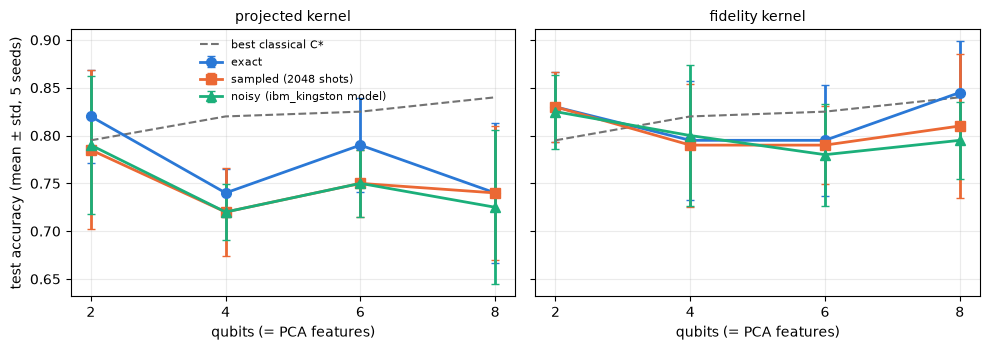

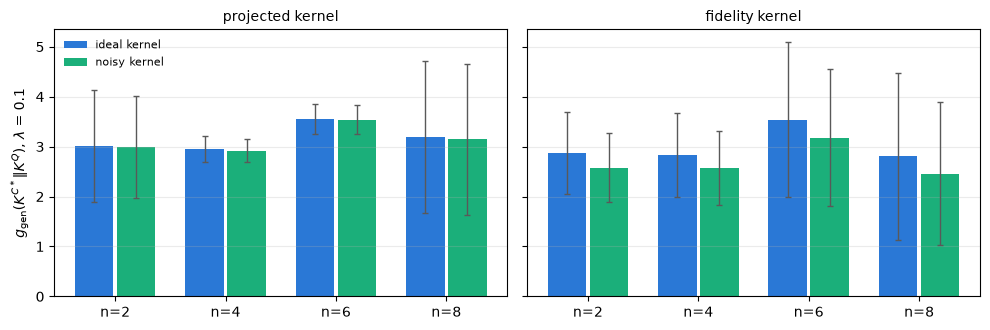

saved figures to E:\LUMS\Semester 3\Quantum Machine Learning\Project\AI631-Projected-Quantum-Kernels\results\figures


In [9]:
figdir = RESULTS / "figures"
figdir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (name, rows) in zip(axes, [("projected kernel", proj_noise), ("fidelity kernel", fid_noise)]):
    for key, lab, c, mk in [("exact", "exact", "#2a78d6", "o"), ("sampled", "sampled (2048 shots)", "#eb6834", "s"),
                            ("noisy", "noisy (ibm_kingston model)", "#1baf7a", "^")]:
        m = [np.mean([r[key]["acc"] for r in rows if r["n_qubits"] == n]) for n in N_LIST]
        s = [np.std([r[key]["acc"] for r in rows if r["n_qubits"] == n]) for n in N_LIST]
        ax.errorbar(N_LIST, m, yerr=s, color=c, marker=mk, markersize=7, linewidth=2, capsize=3, label=lab)
    m = [np.mean([r["acc_c_star"] for r in rows if r["n_qubits"] == n]) for n in N_LIST]
    ax.plot(N_LIST, m, color="0.45", linestyle="--", linewidth=1.5, label="best classical C*")
    ax.set_title(name, fontsize=10)
    ax.set_xticks(N_LIST)
    ax.set_xlabel("qubits (= PCA features)")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("test accuracy (mean $\\pm$ std, 5 seeds)")
axes[0].legend(frameon=False, fontsize=8, loc="best")
fig.tight_layout()
fig.savefig(figdir / "noise_accuracy_levels.png", dpi=200)
plt.show()

x, w = np.arange(len(N_LIST)), 0.38
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (name, rows) in zip(axes, [("projected kernel", proj_noise), ("fidelity kernel", fid_noise)]):
    for k, (key, lab, c) in enumerate([("g_exact", "ideal kernel", "#2a78d6"), ("g_noisy", "noisy kernel", "#1baf7a")]):
        m = [np.mean([r[key] for r in rows if r["n_qubits"] == n]) for n in N_LIST]
        s = [np.std([r[key] for r in rows if r["n_qubits"] == n]) for n in N_LIST]
        ax.bar(x + (k - 0.5) * w, m, w * 0.92, yerr=s, color=c, capsize=2,
               error_kw=dict(elinewidth=1, ecolor="0.35"), label=lab)
    ax.set_title(name, fontsize=10)
    ax.set_xticks(x, [f"n={n}" for n in N_LIST])
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel(r"$g_{\mathrm{gen}}(K^{C^\ast}\|K^Q)$, $\lambda$ = 0.1")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(figdir / "noise_g_ideal_vs_noisy.png", dpi=200)
plt.show()
print("saved figures to", figdir)

## 6. Week 3: four-level comparison on one real-hardware run (seed 0, $n=6$)

The same 120 images (80 train + 40 test) at four levels: **exact** (perfect math), **sampled** (2048 shots), **noisy model** (`FakeKingston`, section 2) and **real hardware** (`ibm_kingston`, notebook 07). We compare the Pauli features qubit by qubit. Noise that pushes states towards the maximally mixed state shrinks every expectation value by a factor; we estimate this **shrink factor** per qubit as the least-squares slope of noisy (or hardware) features against exact ones (1 = no shrink).

In [10]:
SEED_HW, N_HW = 0, 6
hw = json.loads(result_path("tables", "hardware_projected", SEED_HW, N_HW, "json").read_text())
p_hw = load("projected_v2", SEED_HW, N_HW)
a_hw = p_hw["best"]["alpha"]
enc_hw = encoding_circuit(N_HW, LAYERS)
Xtr, ytr, Xte, yte = get_split(SEED_HW)
tf = make_preprocessor(N_HW, a_hw)(Xtr)
Atr, Ate = tf(Xtr), tf(Xte)
A_all = np.vstack([Atr, Ate])

F4 = {"exact": pauli_features_exact(enc_hw, A_all),
      "sampled": np.vstack([pauli_features_sampled(enc_hw, Atr, shots=SHOTS, seed=SEED_HW),
                            pauli_features_sampled(enc_hw, Ate, shots=SHOTS, seed=SEED_HW + 1)]),
      "noisy model": np.vstack([np.load(result_path("features", "pauli_noisy_train", SEED_HW, N_HW, "npy")),
                                np.load(result_path("features", "pauli_noisy_test", SEED_HW, N_HW, "npy"))]),
      "hardware": np.load(result_path("features", "pauli_hardware_all", SEED_HW, N_HW, "npy"))}
Fe = F4["exact"]

def shrink(F, k, j):
    x, y = Fe[:, k, j], F[:, k, j]
    return float(x @ y / (x @ x))              # least-squares slope through the origin

rows = {}
for name in ["sampled", "noisy model", "hardware"]:
    F = F4[name]
    rows[name] = dict(err_q=np.abs(F - Fe)[..., [0, 2]].mean(axis=(0, 2)),     # X and Z (Y is 0 ideally)
                      shrink_Z=np.array([shrink(F, k, 2) for k in range(N_HW)]),
                      shrink_X=np.array([shrink(F, k, 0) for k in range(N_HW)]),
                      mean_Y=F[..., 1].mean(axis=0))

print(f"seed {SEED_HW}, n={N_HW}, 120 images; hardware job {hw.get('backend')} (notebook 07)")
for title, key, fmt in [("mean |feature - exact| (X and Z)", "err_q", "{:>8.3f}"),
                        ("shrink factor of <Z>", "shrink_Z", "{:>8.3f}"),
                        ("shrink factor of <X>", "shrink_X", "{:>8.3f}"),
                        ("mean <Y> (ideal 0)", "mean_Y", "{:>+8.4f}")]:
    print(f"\n{title}")
    print(f"{'qubit':<14}" + "".join(f"{k:>8}" for k in range(N_HW)) + f"{'mean':>9}")
    for name, r in rows.items():
        v = r[key]
        print(f"{name:<14}" + "".join(fmt.format(x) for x in v) + fmt.format(v.mean()).rjust(9))
print("\nhardware readout error p(1|0):", np.round(hw["readout_p10"], 3))
print("hardware readout error p(0|1):", np.round(hw["readout_p01"], 3))

print(f"\n{'level':<30}{'test acc':>9}{'Delta A':>9}{'g':>7}{'Bloch':>8}")
for r in hw["levels"]:
    print(f"{r['level']:<30}{r['acc']:>9.3f}{r['delta_A']:>+9.3f}{r['g']:>7.2f}{r['bloch']:>8.3f}")
_ = result_path("tables", "four_level", SEED_HW, N_HW, "json").write_text(json.dumps(
    {name: {k: v.tolist() for k, v in r.items()} for name, r in rows.items()}, indent=2))   # _ = hides the byte count

seed 0, n=6, 120 images; hardware job ibm_kingston (notebook 07)

mean |feature - exact| (X and Z)
qubit                0       1       2       3       4       5     mean
sampled          0.012   0.015   0.017   0.015   0.015   0.017    0.015
noisy model      0.018   0.114   0.019   0.018   0.022   0.019    0.035
hardware         0.022   0.026   0.023   0.022   0.022   0.025    0.023

shrink factor of <Z>
qubit                0       1       2       3       4       5     mean
sampled          0.999   1.000   0.998   0.999   0.990   0.999    0.997
noisy model      0.978   0.664   0.969   0.967   0.935   0.958    0.912
hardware         0.970   0.967   0.953   0.947   0.946   0.921    0.950

shrink factor of <X>
qubit                0       1       2       3       4       5     mean
sampled          1.009   0.992   1.005   0.999   0.999   0.997    1.000
noisy model      0.987   0.651   0.978   0.975   0.956   0.978    0.921
hardware         0.969   0.936   0.952   0.970   0.969   0.973   

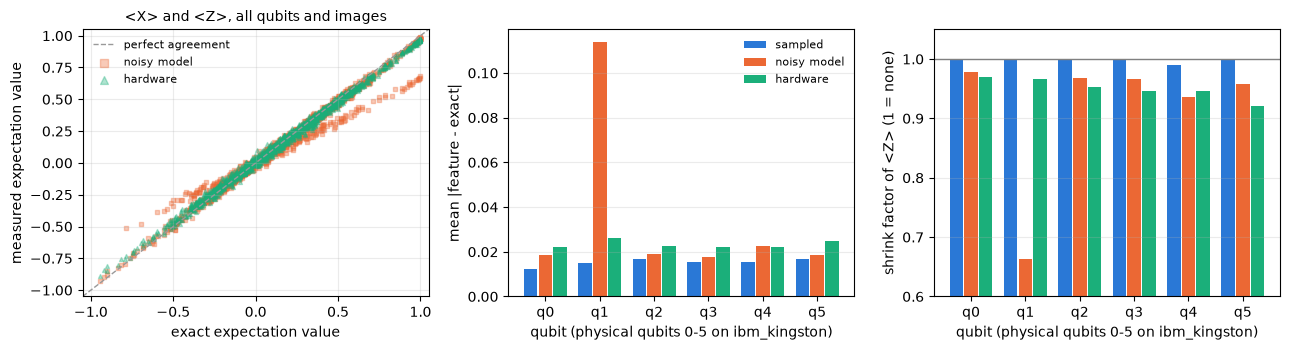

saved four_level_features.png


In [11]:
LV = [("sampled", "#2a78d6", "o"), ("noisy model", "#eb6834", "s"), ("hardware", "#1baf7a", "^")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

ax = axes[0]                                   # all <Z> and <X> values: level vs exact
lim = [-1.05, 1.05]
ax.plot(lim, lim, color="0.6", linewidth=1, linestyle="--", label="perfect agreement")
for name, c, mk in LV[1:]:
    ax.scatter(Fe[..., [0, 2]].ravel(), F4[name][..., [0, 2]].ravel(), s=8, alpha=0.35,
               color=c, marker=mk, label=name)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("exact expectation value")
ax.set_ylabel("measured expectation value")
ax.set_title("<X> and <Z>, all qubits and images", fontsize=10)
ax.legend(frameon=False, fontsize=8, markerscale=2)
ax.grid(alpha=0.25)

x, w = np.arange(N_HW), 0.27
for ax, key, ylab in [(axes[1], "err_q", "mean |feature - exact|"),
                      (axes[2], "shrink_Z", "shrink factor of <Z> (1 = none)")]:
    for i, (name, c, mk) in enumerate(LV):
        ax.bar(x + (i - 1) * w, rows[name][key], w * 0.92, color=c, label=name)
    ax.set_xticks(x, [f"q{k}" for k in range(N_HW)])
    ax.set_xlabel("qubit (physical qubits 0-5 on ibm_kingston)")
    ax.set_ylabel(ylab)
    ax.grid(axis="y", alpha=0.25)
axes[2].axhline(1, color="0.5", linewidth=1)
axes[2].set_ylim(0.6, 1.05)
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / "figures" / "four_level_features.png", dpi=200)
plt.show()
print("saved four_level_features.png")